# 10 — Compact multi-task temporal convolutional network

**Group 119 — Henrik Remmen (541747)**  
**Kaggle team:** `[119] SINTEF Databreach`

This notebook trains a compact non-causal 1D temporal convolutional network (TCN). It consumes the complete known 168-hour input horizon and predicts all 14 generator schedules simultaneously.

Why this architecture:

- all future price, inflow, and constraint inputs are known at prediction time, so non-causal convolutions are valid;
- dilated convolutions cover most or all of the weekly horizon;
- multi-task outputs can learn same-plant and cross-generator structure;
- depthwise-separable convolutions keep CPU cost and parameter count low;
- BCEWithLogitsLoss supplies numerically stable probability training;
- early stopping uses the actual micro ROC-AUC.

> Apple GPU (MPS) is used automatically when available, with CPU as fallback.


## 1. Setup, reproducibility, and data

In [16]:
from copy import deepcopy
from pathlib import Path
import gc
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.sintef_pipeline import (
    HORIZON,
    RANDOM_SEED,
    build_project_data,
    make_submission,
    micro_auc,
    rows_for_cases,
)

sns.set_theme(style="whitegrid", context="notebook")

DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)
N_THREADS = 12
BATCH_SIZE = 256
MAX_EPOCHS = 60
EARLY_STOPPING_PATIENCE = 8
FEATURE_SET = "full_engineered"

torch.set_num_threads(N_THREADS)

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)

seed_everything()
print("Project root:", ROOT.resolve())
print("Device:", DEVICE)


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project
Device: mps


In [17]:
# DATA/FEATURE CELL — no model training
data = build_project_data(ROOT)
FEATURES = data.feature_sets[FEATURE_SET]
N_FEATURES = len(FEATURES)
N_UNITS = len(data.units)

print("Feature set:", FEATURE_SET)
print("Input features:", N_FEATURES)
print("Output units:", N_UNITS)
print("Cases:", data.n_train_cases, "train +", data.n_test_cases, "test")


Feature set: full_engineered
Input features: 175
Output units: 14
Cases: 2922 train + 725 test


## 2. Fold-wise scaling and sequence tensors

Means and standard deviations are fitted only on each fold's training period. The tensor layout is `case × feature × 168`; targets are `case × unit × 168`.

In [18]:
def fit_scaler(case_ids):
    rows = rows_for_cases(case_ids)
    values = data.X_all.loc[rows, FEATURES].to_numpy(dtype=np.float32)
    mean = values.mean(axis=0, dtype=np.float64).astype(np.float32)
    std = values.std(axis=0, dtype=np.float64).astype(np.float32)
    std[std < 1e-6] = 1.0
    return mean, std

def sequence_inputs(case_ids, mean, std):
    case_ids = np.asarray(case_ids)
    rows = rows_for_cases(case_ids)
    values = data.X_all.loc[rows, FEATURES].to_numpy(dtype=np.float32)
    values = values.reshape(len(case_ids), HORIZON, N_FEATURES)
    values = (values-mean[None, None, :])/std[None, None, :]
    return values.transpose(0, 2, 1).astype(np.float32)

def sequence_targets(case_ids):
    return data.target_cube[np.asarray(case_ids)].astype(np.float32)

def make_loader(X, y=None, shuffle=False, seed=RANDOM_SEED):
    tensors = [torch.from_numpy(X)]
    if y is not None:
        tensors.append(torch.from_numpy(y))
    dataset = TensorDataset(*tensors)
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=False,
        generator=generator,
    )


## 3. Depthwise-separable residual TCN

Five dilation levels with kernel size 5 give a receptive field wider than the 168-hour horizon while using far fewer parameters than ordinary dense convolutions.

In [19]:
class SeparableResidualBlock(nn.Module):
    def __init__(self, channels, dilation, kernel_size=5, dropout=0.15):
        super().__init__()
        padding = dilation*(kernel_size-1)//2
        groups = 8 if channels % 8 == 0 else 1

        self.depthwise_1 = nn.Conv1d(
            channels,
            channels,
            kernel_size,
            padding=padding,
            dilation=dilation,
            groups=channels,
        )
        self.pointwise_1 = nn.Conv1d(channels, channels, 1)
        self.norm_1 = nn.GroupNorm(groups, channels)

        self.depthwise_2 = nn.Conv1d(
            channels,
            channels,
            kernel_size,
            padding=padding,
            dilation=dilation,
            groups=channels,
        )
        self.pointwise_2 = nn.Conv1d(channels, channels, 1)
        self.norm_2 = nn.GroupNorm(groups, channels)

        self.activation = nn.GELU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        residual = x
        x = self.depthwise_1(x)
        x = self.pointwise_1(x)
        x = self.norm_1(x)
        x = self.dropout(self.activation(x))
        x = self.depthwise_2(x)
        x = self.pointwise_2(x)
        x = self.norm_2(x)
        return self.activation(residual + self.dropout(x))


class MultiTaskTCN(nn.Module):
    def __init__(
        self,
        n_features,
        n_units,
        channels=32,
        dilations=(1, 2, 4, 8, 16),
        dropout=0.15,
    ):
        super().__init__()
        self.input_projection = nn.Conv1d(n_features, channels, 1)
        self.blocks = nn.Sequential(*[
            SeparableResidualBlock(
                channels=channels,
                dilation=dilation,
                kernel_size=5,
                dropout=dropout,
            )
            for dilation in dilations
        ])
        self.output_projection = nn.Conv1d(channels, n_units, 1)

    def forward(self, x):
        x = self.input_projection(x)
        x = self.blocks(x)
        return self.output_projection(x)


model_check = MultiTaskTCN(N_FEATURES, N_UNITS)
parameter_count = sum(
    parameter.numel() for parameter in model_check.parameters()
    if parameter.requires_grad
)
print(f"Trainable parameters: {parameter_count:,}")
del model_check


Trainable parameters: 19,214


## 4. Training helpers and purged OOF evaluation

In [20]:
def predict_probabilities(model, loader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for batch in loader:
            X_batch = batch[0].to(DEVICE)
            probabilities = torch.sigmoid(model(X_batch))
            predictions.append(probabilities.cpu().numpy())
    return np.concatenate(predictions).astype(np.float32)

def train_one_fold(train_case_ids, val_case_ids, seed):
    seed_everything(seed)
    mean, std = fit_scaler(train_case_ids)
    X_train = sequence_inputs(train_case_ids, mean, std)
    y_train = sequence_targets(train_case_ids)
    X_val = sequence_inputs(val_case_ids, mean, std)
    y_val = sequence_targets(val_case_ids)

    train_loader = make_loader(
        X_train,
        y_train,
        shuffle=True,
        seed=seed,
    )
    val_loader = make_loader(X_val, shuffle=False, seed=seed)

    model = MultiTaskTCN(N_FEATURES, N_UNITS).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
    )
    criterion = nn.BCEWithLogitsLoss()

    best_auc = -np.inf
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, MAX_EPOCHS+1):
        model.train()
        loss_sum = 0.0
        sample_count = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

            loss_sum += loss.item()*len(X_batch)
            sample_count += len(X_batch)

        val_prediction = predict_probabilities(model, val_loader)
        val_auc = micro_auc(y_val, val_prediction)
        train_loss = loss_sum/sample_count
        scheduler.step(val_auc)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_auc": val_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        print(
            f"epoch={epoch:02d} loss={train_loss:.5f} "
            f"val_auc={val_auc:.6f} "
            f"lr={optimizer.param_groups[0]['lr']:.2e}"
        )

        if val_auc > best_auc + 1e-5:
            best_auc = val_auc
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            break

    model.load_state_dict(best_state)
    val_prediction = predict_probabilities(model, val_loader)

    del X_train, y_train, X_val, y_val, train_loader, val_loader
    gc.collect()

    return {
        "model": model,
        "mean": mean,
        "std": std,
        "prediction": val_prediction,
        "best_epoch": best_epoch,
        "best_auc": best_auc,
        "history": pd.DataFrame(history),
    }


In [21]:
# TRAINING CELL A — three purged chronological TCN folds
tcn_oof = np.full(data.target_cube.shape, np.nan, dtype=np.float32)
fold_rows = []
training_histories = {}
best_epochs = []

for fold_index, fold in enumerate(data.folds):
    started = time.perf_counter()
    result = train_one_fold(
        fold["train_cases"],
        fold["validation_cases"],
        seed=RANDOM_SEED + fold_index,
    )
    val_case_ids = fold["validation_cases"]
    tcn_oof[val_case_ids] = result["prediction"]
    score = micro_auc(
        data.target_cube[val_case_ids],
        result["prediction"],
    )
    elapsed = time.perf_counter()-started
    best_epochs.append(result["best_epoch"])
    training_histories[fold["year"]] = result["history"]
    fold_rows.append({
        "validation_year": fold["year"],
        "micro_auc": score,
        "best_epoch": result["best_epoch"],
        "seconds": elapsed,
    })
    print(
        f"TCN | {fold['year']} | micro AUC={score:.6f} | "
        f"best epoch={result['best_epoch']} | {elapsed:.1f}s"
    )
    del result
    gc.collect()

tcn_fold_scores = pd.DataFrame(fold_rows)
display(tcn_fold_scores.style.format({
    "micro_auc": "{:.6f}",
    "seconds": "{:.1f}",
}))
print("Mean AUC:", tcn_fold_scores["micro_auc"].mean())
print("Worst-fold AUC:", tcn_fold_scores["micro_auc"].min())

artifact_dir = ROOT / "artifacts" / "predictions"
artifact_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    artifact_dir / "tcn_multitask_oof.npz",
    oof=tcn_oof,
)
tcn_fold_scores.to_csv(
    artifact_dir / "tcn_multitask_fold_scores.csv",
    index=False,
)


epoch=01 loss=0.75820 val_auc=0.533187 lr=1.00e-03
epoch=02 loss=0.67061 val_auc=0.597869 lr=1.00e-03
epoch=03 loss=0.61900 val_auc=0.658290 lr=1.00e-03
epoch=04 loss=0.57808 val_auc=0.689209 lr=1.00e-03
epoch=05 loss=0.53744 val_auc=0.719138 lr=1.00e-03
epoch=06 loss=0.49381 val_auc=0.736140 lr=1.00e-03
epoch=07 loss=0.45080 val_auc=0.770902 lr=1.00e-03
epoch=08 loss=0.41497 val_auc=0.790718 lr=1.00e-03
epoch=09 loss=0.39043 val_auc=0.796273 lr=1.00e-03
epoch=10 loss=0.37652 val_auc=0.805765 lr=1.00e-03
epoch=11 loss=0.36279 val_auc=0.802950 lr=1.00e-03
epoch=12 loss=0.35798 val_auc=0.810901 lr=1.00e-03
epoch=13 loss=0.34745 val_auc=0.786211 lr=1.00e-03
epoch=14 loss=0.34152 val_auc=0.831539 lr=1.00e-03
epoch=15 loss=0.33131 val_auc=0.831695 lr=1.00e-03
epoch=16 loss=0.32215 val_auc=0.837092 lr=1.00e-03
epoch=17 loss=0.31510 val_auc=0.843245 lr=1.00e-03
epoch=18 loss=0.30861 val_auc=0.846251 lr=1.00e-03
epoch=19 loss=0.30476 val_auc=0.837279 lr=1.00e-03
epoch=20 loss=0.29928 val_auc=0

,validation_year,micro_auc,best_epoch,seconds
0,2020,0.851763,21,7.2
1,2021,0.916432,60,16.3
2,2022,0.935328,55,17.8


Mean AUC: 0.9011741352388863
Worst-fold AUC: 0.851762624790621


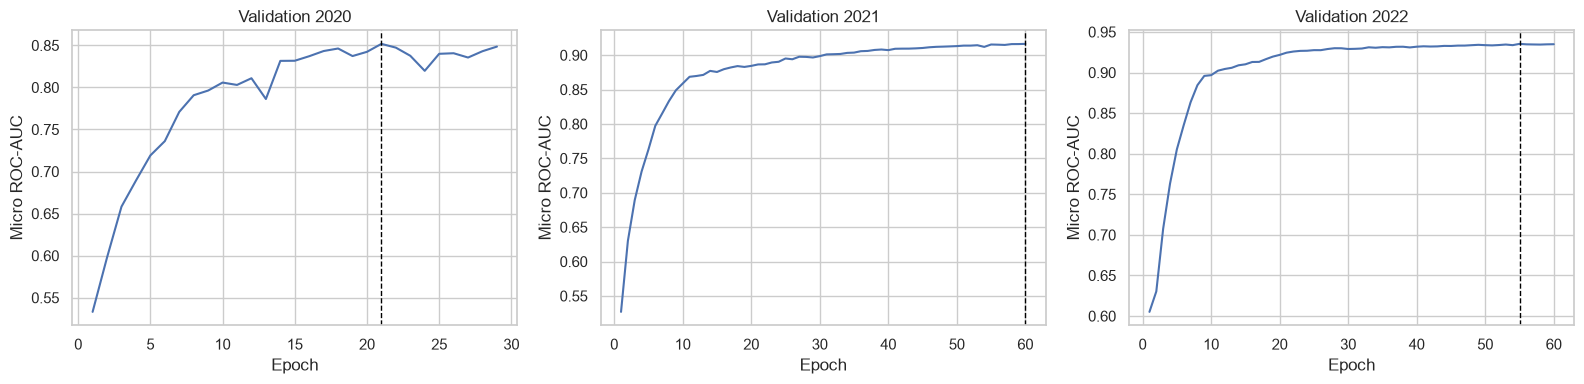

In [22]:
# FAST ANALYSIS CELL — training curves only
fig, axes = plt.subplots(1, len(training_histories), figsize=(16, 4))
for ax, (year, history) in zip(axes, training_histories.items()):
    ax.plot(history["epoch"], history["validation_auc"])
    best_row = history.loc[history["validation_auc"].idxmax()]
    ax.axvline(best_row["epoch"], color="black", linestyle="--", linewidth=1)
    ax.set(
        title=f"Validation {year}",
        xlabel="Epoch",
        ylabel="Micro ROC-AUC",
    )
plt.tight_layout()
plt.show()


## 5. Fixed-epoch full training and submission

The final epoch count is the median best epoch from the chronological folds. No test information is used for early stopping.

In [23]:
def train_fixed_epochs(case_ids, mean, std, n_epochs, seed):
    seed_everything(seed)
    X_train = sequence_inputs(case_ids, mean, std)
    y_train = sequence_targets(case_ids)
    train_loader = make_loader(
        X_train,
        y_train,
        shuffle=True,
        seed=seed,
    )

    model = MultiTaskTCN(N_FEATURES, N_UNITS).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )
    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(1, n_epochs+1):
        model.train()
        loss_sum = 0.0
        sample_count = 0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            loss_sum += loss.item()*len(X_batch)
            sample_count += len(X_batch)
        print(
            f"final epoch={epoch:02d}/{n_epochs} "
            f"loss={loss_sum/sample_count:.5f}"
        )

    del X_train, y_train, train_loader
    gc.collect()
    return model


In [25]:
# TRAINING CELL B — final TCN and submission
all_train_cases = np.arange(data.n_train_cases)
all_test_cases = np.arange(data.n_train_cases, data.n_all_cases)
final_mean, final_std = fit_scaler(all_train_cases)
final_epochs = max(1, int(np.median(best_epochs)))

final_model = train_fixed_epochs(
    all_train_cases,
    final_mean,
    final_std,
    n_epochs=final_epochs,
    seed=RANDOM_SEED,
)
X_test = sequence_inputs(all_test_cases, final_mean, final_std)
test_loader = make_loader(X_test, shuffle=False, seed=RANDOM_SEED)
test_prediction = predict_probabilities(final_model, test_loader)

submission_path, submission = make_submission(
    data,
    test_prediction,
    "tcn_multitask.csv",
)
print("Final epochs:", final_epochs)
print("Saved:", submission_path)
display(submission.iloc[:3, :8])


final epoch=01/55 loss=0.73610
final epoch=02/55 loss=0.65854
final epoch=03/55 loss=0.61248
final epoch=04/55 loss=0.56220
final epoch=05/55 loss=0.51794
final epoch=06/55 loss=0.48012
final epoch=07/55 loss=0.45121
final epoch=08/55 loss=0.42114
final epoch=09/55 loss=0.40698
final epoch=10/55 loss=0.39275
final epoch=11/55 loss=0.39078
final epoch=12/55 loss=0.38409
final epoch=13/55 loss=0.36696
final epoch=14/55 loss=0.35702
final epoch=15/55 loss=0.35186
final epoch=16/55 loss=0.34438
final epoch=17/55 loss=0.33649
final epoch=18/55 loss=0.33194
final epoch=19/55 loss=0.32450
final epoch=20/55 loss=0.31842
final epoch=21/55 loss=0.31285
final epoch=22/55 loss=0.30927
final epoch=23/55 loss=0.30646
final epoch=24/55 loss=0.30158
final epoch=25/55 loss=0.29749
final epoch=26/55 loss=0.29644
final epoch=27/55 loss=0.29356
final epoch=28/55 loss=0.28675
final epoch=29/55 loss=0.28164
final epoch=30/55 loss=0.27623
final epoch=31/55 loss=0.27321
final epoch=32/55 loss=0.27076
final ep

,Run No,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6
0,2923,0.427021,0.357406,0.179813,0.098411,0.075962,0.068765,0.046386
1,2924,0.702642,0.696448,0.711553,0.754319,0.776055,0.831029,0.907105
2,2925,0.827815,0.835155,0.851956,0.892062,0.938212,0.965818,0.983380


### Kaggle description

`Multi-task TCN – 168-hour context and joint 14-unit outputs`

The TCN is promoted only if it is competitive by itself or contributes a clear low-correlation OOF ensemble gain.
